In [15]:
from config import *
import Minimal_Model_1D as mm1D
import Operators2D as O2d

In [16]:
def compute_transforms_and_multiply(n, sigma, lambda_, a):
    gaussian_array = np.random.normal(loc=0, scale=sigma, size=n)
    ft_gaussian = np.fft.fft(gaussian_array)
    j = np.arange(n) 
    exponential_array =  np.exp(-a * np.abs(j)/ lambda_)
    ft_exponential = np.fft.fft(exponential_array)
    product_of_coefficients = ft_gaussian *  np.abs(ft_exponential)
    ift_result = np.fft.ifft(product_of_coefficients)
    variance = np.var(np.abs(ift_result))

    s = 0 

    for i in range(n):

        s = s + math.exp(-i*2*a/lambda_)

    #print(s)

    return ift_result, variance, exponential_array, s


8.767757284045533


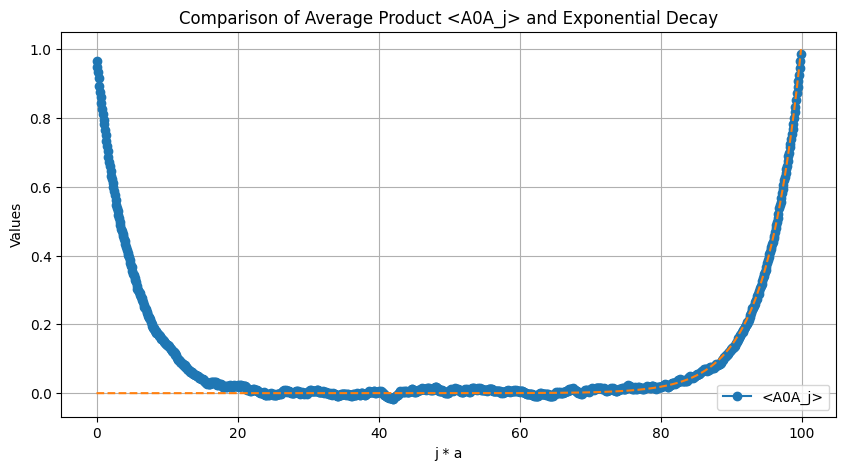

In [25]:
# Parameters
n = 1000  # Array size
sigma = 1  # Standard deviation
lambda_ = 5.0  # Decay constant
a = 0.1  # Lattice spacing
iterations = 10000

# Initialize array to store average results
average_product = np.zeros(n)

# Initialize var_Avg store average results
var_Avg = 0 


# Store the last exponential array for plotting
last_exp_array = None

# Run the simulation for the specified number of iterations
for _ in range(iterations):
    ift_result, v, exp_array, s = compute_transforms_and_multiply(n, sigma, lambda_, a)
    average_product += np.real((ift_result[999] * ift_result)/s)
    var_Avg += v
    last_exp_array = exp_array  # Store the last used exponential array

# Compute the average by dividing by the number of iterations
average_product /= iterations
var_Avg /= iterations


print(var_Avg)

# Plotting
plt.figure(figsize=(10, 5))
plt.plot(a * np.arange(n), average_product, label='<A0A_j>', marker='o')
plt.plot(a * np.arange(n), np.exp(-np.abs(999-np.arange(n))*a/lambda_), ls='dashed')
#plt.plot(a * np.arange(n), last_exp_array, label='Exponential Decay', color='red')
plt.xlabel('j * a')
plt.ylabel('Values')
plt.title('Comparison of Average Product <A0A_j> and Exponential Decay')
plt.legend()
plt.grid(True)
plt.show()
